# <font color="blue"><b>The Tuning Trilemma: Balancing Performance, Memory, and Cost in Medical Instruction Tuning</b></font>

---

## Problem Statement

Large language models are expensive to adapt. **Full fine-tuning** updates every weight in the model — it works well but needs a lot of GPU memory and compute, which puts it out of reach on modest hardware. Two parameter-efficient methods promise most of the quality for a fraction of the cost:

- **LoRA** freezes the model and trains only small low-rank adapter matrices (well under 1% of the parameters).
- **QLoRA** goes further — it stores the frozen model in **4-bit**, then trains the same LoRA adapters on top, cutting memory again.

In this assignment you will put these three methods on a real task: teaching **Qwen2.5-0.5B-Instruct** to answer medical instructions from the **AlpaCare-MedInstruct-52k** dataset (each example is `instruction (+ optional input) → reference answer`). You will fine-tune the **same model on the same data three ways**, then measure what each approach costs and what it buys.

**The central question:** *given a fixed model, a fixed dataset, and a single free T4 GPU, is it worth updating all ~500M parameters — or does a low-rank slice (LoRA), or a low-rank slice over a 4-bit backbone (QLoRA), get you almost the same answer quality for far less memory?* You will also compare **two LoRA ranks (r = 8 and r = 16)** for both LoRA and QLoRA, to see how adapter capacity trades against cost.

---

## What You Will Do

You will build the pipeline end-to-end, as a hand-written training loop (a torch `Dataset`, a `collate` function, and `DataLoader`s — no `Trainer`), reused across all three methods:

1. **Imports & seed** — set up the environment reproducibly. *(provided)*
2. **Configuration** — model, data sizes, and all hyperparameters in one place. *(provided)*
3. **Helper functions** — LoRA/QLoRA configs, parameter counting, memory utilities. *(provided)*
4. **Load dataset + statistics** — take 300 / 30 / 30 for train / val / test; inspect fields and lengths.
5. **Dataset, collate & loaders** — build the prompt with the chat template, mark answer tokens with an offset-based mask, pad batches, and create the three loaders.
6. **Model load + IFT training** — write the masked-loss + shared training loop, then run **full instruction fine-tuning**.
7. **LoRA** — freeze the backbone and train adapters at **r = 8 and r = 16**.
8. **QLoRA** — repeat the rank sweep with a **4-bit NF4** backbone.
9. **Test evaluation** — greedy-generate on the test set and score every run with **ROUGE-L** and **BERTScore-F1**.
10. **Plots** — per-epoch train vs validation loss for every run.
11. **Error analysis** — inspect the best model's answers vs the references and summarise the failure modes.
12. **Parameter analysis** — compare quality against % trainable parameters, peak memory, and training time.

**How the notebook is organised**
- Cells marked **`# ── PROVIDED ──`** are already written — just run them in order.
- You only need to write the code inside **`## CODE HERE ##`**.
- Every step with a red **`[marks]`** tag is graded: complete the code where indicated and write the **`Your Answer`** reflection.
- Reflections must **cite the actual numbers your run produced** — not generic descriptions.

**Runtime:** Colab **free T4 GPU**. We deliberately use a small data subset and short runs so all methods finish in one session. Select the T4 runtime and run top-to-bottom after a restart. No API key needed.

> **Safety note.** This is an exercise on a 0.5B model with machine-generated references. Its outputs are **not** clinically reliable and must never guide real medical decisions.

---

## Mark Distribution

| Step | Topic | Marks |
|------|-------|-------|
| 1 | Imports & seed | 0 *(provided)* |
| 2 | Configuration | 0 *(provided)* |
| 3 | Helper functions (LoRA / QLoRA) | 0 *(provided)* |
| 4 | Load dataset + statistics | 8 |
| 5 | Dataset, collate & loaders | 14 |
| 6 | Model load + IFT training | 20 |
| 7 | LoRA (r = 8 and r = 16) | 14 |
| 8 | QLoRA (r = 8 and r = 16) | 14 |
| 9 | Test evaluation (ROUGE-L + BERTScore) | 10 |
| 10 | Plots (train vs validation) | 6 |
| 11 | Error analysis | 8 |
| 12 | Parameter analysis | 6 |
| | **Total** | **100** |

Most marks sit where the core learning is: the training loop and full IFT (Step 6), and the data pipeline plus the two PEFT methods (Steps 5, 7, 8). Steps 1–3 are provided scaffolding and carry no marks.

---

> **Learner note:** Use a fresh T4 runtime and execute all cells. Reserve EOS within `MAX_LEN`, ensure at least one supervised answer token, and compare LoRA/QLoRA at matched ranks. Report isolated GPU-memory measurements when possible.

In [ ]:
# Some package installation.
!pip install -q evaluate rouge_score bert_score "bitsandbytes>=0.43"

In [ ]:
# Avoid a torchao/T4 incompatibility that can surface with peft/quantised stacks.
!pip uninstall -y -q torchao

### <font color="blue"><b>Step 1: Imports and Seed Setting</b></font>  *(provided — just run)*

Import the libraries used throughout — PyTorch and `torch.utils.data`, Hugging Face `transformers` / `datasets` / `peft`, and plotting — and fix a single random seed across `random`, NumPy, and PyTorch (`seed_everything`) so every run is reproducible.

> `# ── PROVIDED ──` This cell is written for you. Run it and move on.

In [ ]:
# ============================================================
# 1. Imports and Seed Setting
# ---PROVIDED ------------------------------------------------
# ============================================================
import os, gc, math, time, random, warnings, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModelForCausalLM,
                          BitsAndBytesConfig, get_cosine_schedule_with_warmup,
                          set_seed)
from peft import (LoraConfig, get_peft_model, prepare_model_for_kbit_training,
                  TaskType)

warnings.filterwarnings("ignore")

SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    set_seed(seed)

seed_everything()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


### <font color="blue"><b>Step 2: Configuration</b></font>  *(provided — just run)*

All the knobs in one place: the model ID, dataset split sizes (`N_TRAIN` / `N_VAL` / `N_TEST`), the sequence-length budget (`MAX_LEN`), and the training hyperparameters — batch size, gradient accumulation, epochs, the two learning rates (`LR_FULL`, `LR_LORA`), and the LoRA ranks. The rest of the notebook reads from these constants, so change behaviour here rather than editing later cells.

> `# ── PROVIDED ──` This cell is written for you. Run it and move on.

In [ ]:
# ============================================================
#  Step 2: Configuration
# ---PROVIDED ------------------------------------------------
# ============================================================
MODEL_ID   = "Qwen/Qwen2.5-0.5B-Instruct"

# ---- Data ----
N_TRAIN    = 300
N_VAL      = 30
N_TEST     = 30
MAX_LEN    = 256        # token budget per (prompt + answer) example

# ---- Training ----
BATCH_SIZE = 4          # small: fits a free T4 - if not fit please reduce it
GRAD_ACCUM = 1          # effective batch = BATCH_SIZE * GRAD_ACCUM
EPOCHS     = 3
WARMUP_RATIO  = 0.05
MAX_GRAD_NORM = 1.0

LR_FULL    = 1e-5       # full fine-tuning: small LR (all weights move)
LR_LORA    = 2e-4       # LoRA / QLoRA: frozen backbone -> larger LR is safe

# ---- LoRA / QLoRA ----
LORA_R       = 16
LORA_ALPHA   = 32
LORA_DROPOUT = 0.05

# ---- Evaluation ----
EVAL_N     = N_TEST         # number of held-out test prompts to score

### <font color="blue"><b>Step 3: Helper Functions</b></font>  *(provided — just run)*

Small utilities reused across every method: `count_trainable` (trainable-vs-total parameter counts), `get_lora_config` / `get_bnb_config` (the shared LoRA and 4-bit NF4 quantisation settings), and `gpu_mem_gb` / `free_memory` (peak-memory reporting and VRAM cleanup between runs).

> `# ── PROVIDED ──` This cell is written for you. Run it and move on.

In [ ]:
# ============================================================
#  Step 3: Helper Functions (LoRA / QLoRA)
# ---PROVIDED ------------------------------------------------
# ============================================================

def count_trainable(model):
    """Return (trainable, total, percent-trainable) parameter counts."""
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total     = sum(p.numel() for p in model.parameters())
    return trainable, total, 100 * trainable / total


def get_lora_config():
    """Standard LoRA config for Qwen2.5 (attention + MLP projections)."""
    return LoraConfig(
        task_type=TaskType.CAUSAL_LM,
        r=LORA_R,
        lora_alpha=LORA_ALPHA,
        lora_dropout=LORA_DROPOUT,
        bias="none",
        target_modules=["q_proj", "k_proj", "v_proj", "o_proj",
                        "gate_proj", "up_proj", "down_proj"],
    )


def get_bnb_config():
    """4-bit NF4 quantisation config for QLoRA (fp16 compute for T4)."""
    return BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True,
        bnb_4bit_compute_dtype=torch.float16,
    )


def gpu_mem_gb():
    """Peak GPU memory used since the last reset, in GB."""
    return torch.cuda.max_memory_allocated() / 1e9 if torch.cuda.is_available() else 0.0


def free_memory(*objs):
    """Delete big objects (models/trainers) and reclaim GPU memory between runs."""
    for o in objs:
        try: del o
        except Exception: pass
    gc.collect()
    torch.cuda.empty_cache()
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()

## <font color="blue"><b>Step 4: Load Dataset and Statistics</b></font>  <font color="red">**[8 marks]**</font>

Load **AlpaCare-MedInstruct-52k** and randomly take **300 train / 30 validation / 30 test**. Each row is just `instruction (+ optional input) → output`, where `output` is a reference answer. The dataset stores the literal token `<noinput>` when there is no extra context, so blank that out first.

Then compute a few basic statistics on the training split: the fraction of rows with a non-empty `input`, and the token-length distribution of `instruction + input + output` (mean / median / p95 / max), plus a length histogram.

**Marks:** code **[<font color="red">4 marks</font>]** — correct load, `<noinput>` handling, 300/30/30 split, and the statistics + histogram; reflection **[<font color="red">4 marks</font>]** — see below.

Original dataset shape: (52002, 3)
Dataset columns: ['output', 'input', 'instruction']

Dataset split sizes:
Training: 300
Validation: 30
Test: 30

---- Training Dataset Statistics ----
Fraction of rows with non-empty input: 0.6933
Percentage of rows with non-empty input: 69.33 %

Token Length Distribution:
Mean: 237.84
Median: 270.5
95th percentile: 365.0
Maximum: 495


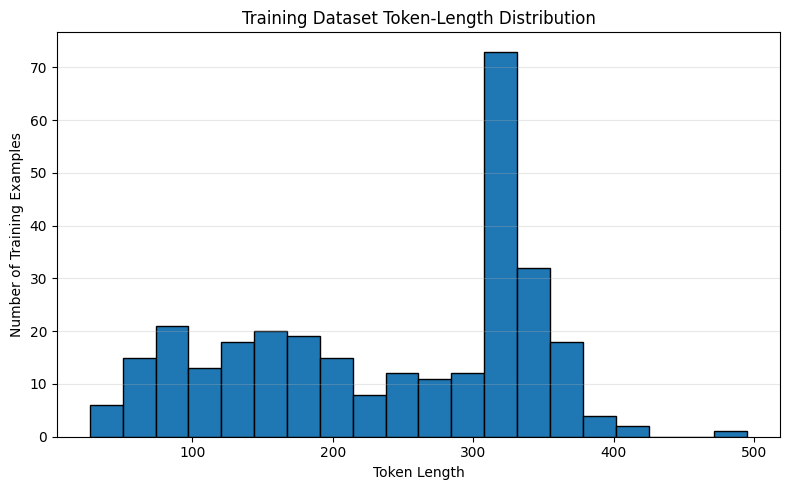

In [ ]:

# ============================================================
# Step 4: Load Dataset and Statistics
# ============================================================

# Load the dataset and convert to pandas DataFrame
dataset = load_dataset("lavita/AlpaCare-MedInstruct-52k", split="train")
df = dataset.to_pandas()

print("Original dataset shape:", df.shape)
print("Dataset columns:", df.columns.tolist())

# The dataset stores the literal token "<noinput>" when there is no extra context.
df["input"] = (
    df["input"]
    .fillna("")
    .astype(str)
    .str.replace("<noinput>", "", regex=False)
    .str.strip()
)

# Shuffle once, then slice off the splits by index.
df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)

train_df = df.iloc[:N_TRAIN].reset_index(drop=True)
val_df = df.iloc[N_TRAIN:N_TRAIN + N_VAL].reset_index(drop=True)
test_df = df.iloc[N_TRAIN + N_VAL:N_TRAIN + N_VAL + N_TEST].reset_index(drop=True)

print("\nDataset split sizes:")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

# ---- Basic statistics on the training split ----
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

tokenizer.padding_side = "right"

frac_with_input = (train_df["input"] != "").mean()

def combined_len(r):
    text = r["instruction"] + " " + r["input"] + " " + r["output"]
    return len(tokenizer(text, add_special_tokens=False)["input_ids"])

# Calculate token lengths for all training examples
train_lengths = train_df.apply(combined_len, axis=1)

# Print training dataset statistics
print("\n---- Training Dataset Statistics ----")
print("Fraction of rows with non-empty input:", round(frac_with_input, 4))
print("Percentage of rows with non-empty input:", round(frac_with_input * 100, 2), "%")

print("\nToken Length Distribution:")
print("Mean:", round(train_lengths.mean(), 2))
print("Median:", train_lengths.median())
print("95th percentile:", train_lengths.quantile(0.95))
print("Maximum:", train_lengths.max())

# Plot token length histogram
plt.figure(figsize=(8, 5))
plt.hist(train_lengths, bins=20, edgecolor="black")
plt.xlabel("Token Length")
plt.ylabel("Number of Training Examples")
plt.title("Training Dataset Token-Length Distribution")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()




### ✍️ Step 4 Reflection  <font color="red">[4 marks]</font>

**[Your Answer]** must cover:
- The three fields (`instruction`, `input`, `output`), what each holds, and roughly what fraction of rows use a non-empty `input`. **<font color="red">1 marks</font>**
- The token-length statistics you printed (mean / median / p95 / max) and the `MAX_LEN` you will adopt because of them — justify the choice against the p95. **<font color="red">2 marks</font>**
- That `output` is a *machine-generated* reference (text-davinci-003), and what that implies for treating it as ground truth when scoring models later. **<font color="red">1 marks</font>**

*Cite the actual numbers your run produced.*

## <font color="blue"><b>Step 5: Dataset, Collate, and DataLoaders</b></font>  <font color="red">**[14 marks]**</font>

Build the input pipeline as a hand-written `torch.utils.data.Dataset` (like the DPO demo), with tokenisation deferred to a `collate` function:

- **`SFTDataset`** — holds `(prompt, answer)` text pairs. The prompt is rendered with the tokenizer's **chat template** (instruction → *user* turn, primed to answer).
- **`tokenize_example`** — tokenises the full `prompt + answer` **once** and uses the **offset mapping** to mark exactly where the answer begins, producing a `comp_mask` (1 = answer token, 0 = prompt token).
- **`collate`** — pads a batch to its longest sequence and returns `input_ids`, `attn`, and `comp_mask`.
- **Three DataLoaders** — `train_loader` (shuffled), `val_loader`, `test_loader`.

Finally, print the **first full training batch** to confirm the shapes and the answer/prompt masking.

**Marks:** code <font color="red">**[10 marks]**</font> — `SFTDataset` + chat-template prompt, offset-based `comp_mask`, correct padded `collate`, three loaders, and the batch print; reflection <font color="red">**[4 marks]**</font> — see below.

In [ ]:

# ============================================================
# Step 5: Dataset, Collate, and DataLoaders
# ============================================================

SYSTEM_MSG = "You are a helpful medical assistant. Answer accurately and safely."

# Build the Qwen chat-template prompt
def build_prompt(instruction, input_text):
    user_content = instruction.strip()
    if input_text.strip():
        user_content += "\n\nAdditional context:\n" + input_text.strip()

    msgs = [
        {"role": "system", "content": SYSTEM_MSG},
        {"role": "user", "content": user_content}
    ]
    return tokenizer.apply_chat_template(
        msgs, tokenize=False, add_generation_prompt=True
    )


class SFTDataset(Dataset):
    """Holds (prompt_text, answer_text) pairs; tokenisation is deferred to collate()."""
    def __init__(self, frame):
        self.rows = [{"prompt": build_prompt(r["instruction"], r["input"]),
                      "answer": r["output"].strip()}
                     for _, r in frame.iterrows()]

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        return self.rows[i]


# Tokenize the complete sequence and create the completion mask using offsets
def tokenize_example(prompt, answer):
    full_text = prompt + answer + tokenizer.eos_token
    answer_start = len(prompt)

    encoded = tokenizer(
        full_text,
        add_special_tokens=False,
        return_offsets_mapping=True,
        truncation=True,
        max_length=MAX_LEN
    )

    ids = encoded["input_ids"]
    offsets = encoded["offset_mapping"]

    mask = [
        1 if end > answer_start else 0
        for start, end in offsets
    ]

    return ids, mask


# Pad examples and create attention and completion masks
def collate(batch):
    encoded_batch = [
        tokenize_example(item["prompt"], item["answer"])
        for item in batch
    ]

    max_batch_len = max(len(ids) for ids, mask in encoded_batch)
    batch_size = len(encoded_batch)

    input_ids = torch.full(
        (batch_size, max_batch_len),
        tokenizer.pad_token_id,
        dtype=torch.long
    )
    attn = torch.zeros((batch_size, max_batch_len), dtype=torch.long)
    comp_mask = torch.zeros((batch_size, max_batch_len), dtype=torch.long)

    for i, (ids, mask) in enumerate(encoded_batch):
        seq_len = len(ids)
        input_ids[i, :seq_len] = torch.tensor(ids, dtype=torch.long)
        attn[i, :seq_len] = 1
        comp_mask[i, :seq_len] = torch.tensor(mask, dtype=torch.long)

    return input_ids, attn, comp_mask


# ---- Three DataLoaders ----
train_dataset = SFTDataset(train_df)
val_dataset = SFTDataset(val_df)
test_dataset = SFTDataset(test_df)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate,
    num_workers=0
)

print(f"Train batches : {len(train_loader)}")
print(f"Val batches   : {len(val_loader)}")
print(f"Test batches  : {len(test_loader)}")


# ---- Print the first FULL batch of the train loader ----
input_ids, attn, comp_mask = next(iter(train_loader))

print("\n---- First Training Batch ----")
print("Input IDs shape:", input_ids.shape)
print("Attention mask shape:", attn.shape)
print("Completion mask shape:", comp_mask.shape)

print("\nInput IDs:")
print(input_ids)

print("\nAttention Mask:")
print(attn)

print("\nCompletion Mask:")
print(comp_mask)

supervised_tokens = comp_mask.sum().item()
masked_prompt_tokens = ((comp_mask == 0) & (attn == 1)).sum().item()
padding_tokens = (attn == 0).sum().item()

print("\n---- Token Counts ----")
print("Supervised answer tokens:", supervised_tokens)
print("Masked prompt tokens:", masked_prompt_tokens)
print("Padding tokens:", padding_tokens)
print("Total valid tokens:", attn.sum().item())


Train batches : 75
Val batches   : 8
Test batches  : 8

---- First Training Batch ----
Input IDs shape: torch.Size([4, 256])
Attention mask shape: torch.Size([4, 256])
Completion mask shape: torch.Size([4, 256])

Input IDs:
tensor([[151644,   8948,    198,  ...,    323,  10006,     37],
        [151644,   8948,    198,  ...,  18472,  88285,  13621],
        [151644,   8948,    198,  ...,   6028,   9751,  28571],
        [151644,   8948,    198,  ..., 151643, 151643, 151643]])

Attention Mask:
tensor([[1, 1, 1,  ..., 1, 1, 1],
        [1, 1, 1,  ..., 1, 1, 1],
        [1, 1, 1,  ..., 1, 1, 1],
        [1, 1, 1,  ..., 0, 0, 0]])

Completion Mask:
tensor([[0, 0, 0,  ..., 1, 1, 1],
        [0, 0, 0,  ..., 1, 1, 1],
        [0, 0, 0,  ..., 1, 1, 1],
        [0, 0, 0,  ..., 0, 0, 0]])

---- Token Counts ----
Supervised answer tokens: 617
Masked prompt tokens: 401
Padding tokens: 6
Total valid tokens: 1018


### ✍️ Step 5 Reflection  <font color="red">**[4 marks]**</font>

**[Your Answer]** must cover:
- Why the prompt uses the tokenizer's **chat template** for an `-Instruct` model (special tokens must match what the model saw in pre-training). <font color="red">**[1]**</font>
- What `comp_mask` encodes and why we compute the loss on the **answer tokens only** (completion-only). <font color="red">**[1]**</font>
- Why tokenising `prompt + answer` **once with offsets** is more correct than tokenising them separately and concatenating (avoids token-merge drift at the boundary). <font color="red">**[1]**</font>
- From the printed batch: the supervised-vs-masked token counts, and why padding fills `input_ids` with the pad token but `comp_mask` with 0. <font color="red">**[1]**</font>

*Cite the actual numbers your run produced.*

## <font color="blue"><b>Step 6: Model Loading and Full Instruction Fine-Tuning (IFT)</b></font>  <font color="red">**[20 marks]**</font>

This is the core of the notebook. First define the training machinery that all three methods reuse, then run full fine-tuning:

- **`batch_loss`** — the causal-LM next-token loss, but computed over **answer tokens only** (using `comp_mask`), so the model is never scored on re-typing the prompt.
- **`eval_loss`** — averages `batch_loss` over a whole loader (no gradients), used for validation.
- **`train_model`** — the shared manual training loop: gradient accumulation, warmup → cosine schedule, gradient clipping, per-epoch train/val history, and early stopping on validation loss. Returns the best model plus its history, training time, and peak memory.

Then load Qwen2.5-0.5B in **fp32** (pure fp16 full fine-tuning overflows on this model), confirm ~100% of parameters are trainable, run **full IFT** with the small learning rate `LR_FULL`, and print the per-epoch train/val losses.

**Marks:** code <font color="red">**[14 marks]**</font> — correct answer-only `batch_loss`, the `train_model` loop (accumulation, schedule, clipping, early stopping, history), fp32 model load, and the IFT run with per-epoch report; reflection <font color="red">**[6 marks]**</font> — see below.

In [ ]:

# ============================================================
# Step 6: Load Model and Full Instruction Fine-Tuning (IFT)
# ============================================================

# ---- Loss over ANSWER tokens only (comp_mask == 1) ----
def batch_loss(model, input_ids, attn, comp_mask):
    """Mean next-token NLL over answer tokens for ONE batch."""
    outputs = model(input_ids=input_ids, attention_mask=attn)
    logits = outputs.logits

    # Shift logits and labels for causal next-token prediction
    shift_logits = logits[:, :-1, :].contiguous()
    shift_labels = input_ids[:, 1:].contiguous()
    shift_mask = (comp_mask[:, 1:] * attn[:, 1:]).float()

    tok = F.cross_entropy(
        shift_logits.view(-1, shift_logits.size(-1)),
        shift_labels.view(-1),
        reduction="none"
    ).view(shift_labels.shape)

    return (tok * shift_mask).sum() / shift_mask.sum().clamp(min=1.0)


# ---- Validation loss ----
@torch.no_grad()
def eval_loss(model, loader):
    """Average batch_loss over an entire loader (no gradients)."""
    model.eval()
    tot, n = 0.0, 0

    for input_ids, attn, comp_mask in loader:
        input_ids = input_ids.to(DEVICE)
        attn = attn.to(DEVICE)
        comp_mask = comp_mask.to(DEVICE)

        loss = batch_loss(model, input_ids, attn, comp_mask)
        tot += loss.item()
        n += 1

    return tot / max(n, 1)


# ---- Shared training loop (reused for IFT, LoRA, QLoRA) ----
def train_model(model, lr, tag):
    """
    Manual training loop: gradient accumulation, warmup->cosine schedule,
    gradient clipping, and early stopping on validation loss.
    Returns (best_model, hist, train_time_s, peak_mem_gb).
    hist keys: 'train_loss' & 'val_loss' (per epoch), 'step_loss' (per step).
    """
    seed_everything()
    free_memory()

    optimizer = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr=lr
    )

    trainable_keys = {
        n for n, p in model.named_parameters() if p.requires_grad
    }

    total_steps = math.ceil(len(train_loader) / GRAD_ACCUM) * EPOCHS

    scheduler = get_cosine_schedule_with_warmup(
        optimizer, int(WARMUP_RATIO * total_steps), total_steps
    )

    hist = {"train_loss": [], "val_loss": [], "step_loss": []}
    best_val, best_epoch, best_state, no_improve, PATIENCE = (
        float("inf"), 0, None, 0, 2
    )

    t0 = time.time()

    # Run training and validation for each epoch
    for epoch in range(EPOCHS):
        model.train()
        optimizer.zero_grad(set_to_none=True)

        running_loss = 0.0
        batch_count = 0

        for step, (input_ids, attn, comp_mask) in enumerate(train_loader):
            input_ids = input_ids.to(DEVICE)
            attn = attn.to(DEVICE)
            comp_mask = comp_mask.to(DEVICE)

            loss = batch_loss(model, input_ids, attn, comp_mask)

            (loss / GRAD_ACCUM).backward()

            running_loss += loss.item()
            batch_count += 1
            hist["step_loss"].append(loss.item())

            # Update weights after the configured accumulation steps
            if (step + 1) % GRAD_ACCUM == 0 or (step + 1) == len(train_loader):
                torch.nn.utils.clip_grad_norm_(
                    [p for p in model.parameters() if p.requires_grad],
                    MAX_GRAD_NORM
                )
                optimizer.step()
                scheduler.step()
                optimizer.zero_grad(set_to_none=True)

        train_epoch_loss = running_loss / max(batch_count, 1)
        val_epoch_loss = eval_loss(model, val_loader)

        hist["train_loss"].append(train_epoch_loss)
        hist["val_loss"].append(val_epoch_loss)

        print(
            f"[{tag}] Epoch {epoch + 1}/{EPOCHS} | "
            f"Train Loss: {train_epoch_loss:.4f} | "
            f"Val Loss: {val_epoch_loss:.4f}"
        )

        # Save the best checkpoint and apply early stopping
        if val_epoch_loss < best_val:
            best_val = val_epoch_loss
            best_epoch = epoch + 1
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }
            no_improve = 0
        else:
            no_improve += 1

        if no_improve >= PATIENCE:
            print(f"[{tag}] Early stopping at epoch {epoch + 1}")
            break

    # Restore the best validation checkpoint
    if best_state is not None:
        model.load_state_dict(best_state)

    train_time, peak_mem = time.time() - t0, gpu_mem_gb()

    print(
        f"[{tag}] best epoch = {best_epoch} | "
        f"time = {train_time:.1f}s | "
        f"peak mem = {peak_mem:.2f} GB"
    )

    return model, hist, train_time, peak_mem


# ---- Load model for Full IFT ----
# FP32 is used instead of FP16 for numerical stability.
seed_everything()
free_memory()

full_model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float32
).to(DEVICE)

full_model.config.use_cache = False

trainable, total, pct = count_trainable(full_model)

print("\n---- Full IFT Model Parameters ----")
print(f"Trainable parameters: {trainable:,}")
print(f"Total parameters: {total:,}")
print(f"Percentage trainable: {pct:.2f}%")

# ---- Run Full Instruction Fine-Tuning ----
full_model, full_hist, full_time, full_peak_mem = train_model(
    full_model, LR_FULL, "Full IFT"
)

# ---- Per-epoch loss history ----
print("\nEpoch |  Train Loss | Val Loss")
print("-" * 34)

for ep, (tl, vl) in enumerate(
    zip(full_hist["train_loss"], full_hist["val_loss"]), 1
):
    print(f"  {ep:2d}  |   {tl:.4f}   | {vl:.4f}")


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]


---- Full IFT Model Parameters ----
Trainable parameters: 494,032,768
Total parameters: 494,032,768
Percentage trainable: 100.00%
[Full IFT] Epoch 1/3 | Train Loss: 1.0902 | Val Loss: 1.0593
[Full IFT] Epoch 2/3 | Train Loss: 0.4892 | Val Loss: 1.1242
[Full IFT] Epoch 3/3 | Train Loss: 0.2055 | Val Loss: 1.2951
[Full IFT] Early stopping at epoch 3
[Full IFT] best epoch = 1 | time = 266.3s | peak mem = 10.74 GB

Epoch |  Train Loss | Val Loss
----------------------------------
   1  |   1.0902   | 1.0593
   2  |   0.4892   | 1.1242
   3  |   0.2055   | 1.2951


### ✍️ Step 6 Reflection  <font color="red">**[6 marks]**</font>

**[Your Answer]** must cover:
- How `batch_loss` supervises **only** the answer tokens (the `comp_mask` shift + masked mean), and how completion-only loss differs from training on the whole sequence. <font color="red">**[2 marks]**</font>
- Where warmup, cosine decay, gradient clipping, and gradient accumulation appear in `train_model`, and your **effective batch size** (`BATCH_SIZE × GRAD_ACCUM`). <font color="red">**[2 marks]**</font>
- Why full IFT is loaded in **fp32** (pure fp16 full fine-tuning overflows on Qwen2.5) and why its learning rate `LR_FULL = 1e-5` is deliberately small. <font color="red">**[1 marks]**</font>
- The per-epoch train/val trend — is the model improving or starting to overfit? <font color="red">**[1 marks]**</font>

*Cite the actual numbers your run produced.*

## <font color="blue"><b>Step 7: LoRA Fine-Tuning — r = 8 and r = 16</b></font>  <font color="red">**[14 marks]**</font>

Now freeze the backbone and train only small low-rank adapter matrices. For a frozen weight `W`, LoRA learns `A` and `B` and adds `(α/r)·B·A` as a correction — so only a tiny fraction of the parameters are trained.

Run LoRA at **two ranks, r = 8 and r = 16**, holding the `alpha/rank` ratio fixed (`alpha = 2·r`) so you isolate the effect of *rank* alone. Reuse the same `train_model` loop, store each run in `lora_runs[rank]`, and report the trainable-parameter percentage and per-epoch losses for both.

*(The `torchao` uninstall here avoids a T4 incompatibility that can otherwise break the peft/quantised path in the next step.)*

**Marks:** code <font color="red">**[8 marks]**</font> — correct `LoraConfig` (rank, alpha, dropout, target modules), the two-rank sweep reusing `train_model`, and the trainable-% + per-epoch report for each rank; reflection <font color="red">**[6 marks]**</font> — see below.

In [ ]:

# ============================================================
# Step 7: LoRA Fine-Tuning (rank sweep: r = 8 and r = 16)
# ============================================================

LORA_RANKS = [8, 16]

def build_lora_model(rank):
    """Fresh fp32 backbone + LoRA adapters at the given rank."""
    seed_everything()
    free_memory()

    base = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        torch_dtype=torch.float32
    ).to(DEVICE)

    base.config.use_cache = False

    cfg = LoraConfig(
        task_type=TaskType.CAUSAL_LM,
        r=rank,
        lora_alpha=2 * rank,
        lora_dropout=LORA_DROPOUT,
        bias="none",
        target_modules=[
            "q_proj", "k_proj", "v_proj", "o_proj",
            "gate_proj", "up_proj", "down_proj"
        ]
    )

    return get_peft_model(base, cfg)


# ---- Run LoRA at each rank ----
lora_runs = {}

for rank in LORA_RANKS:
    print(f"\n{'=' * 50}")
    print(f"Starting LoRA with rank = {rank}")
    print(f"{'=' * 50}")

    model = build_lora_model(rank)

    trainable, total, pct = count_trainable(model)

    print(f"Trainable parameters: {trainable:,}")
    print(f"Total parameters: {total:,}")
    print(f"Percentage trainable: {pct:.4f}%")

    model.print_trainable_parameters()

    model, hist, train_time, peak_mem = train_model(
        model, LR_LORA, f"LoRA-r{rank}"
    )

    lora_runs[rank] = {
        "model": model,
        "hist": hist,
        "time": train_time,
        "mem": peak_mem,
        "pct": pct,
        "trainable": trainable,
        "total": total
    }

    print(f"\nLoRA rank {rank} — Per-epoch losses")
    print("Epoch |  Train Loss | Val Loss")
    print("-" * 34)

    for ep, (tl, vl) in enumerate(
        zip(hist["train_loss"], hist["val_loss"]), 1
    ):
        print(f"  {ep:2d}  |   {tl:.4f}   | {vl:.4f}")

    print()

    # Keep the trained adapters in lora_runs and clear temporary references
    del model
    gc.collect()
    torch.cuda.empty_cache()



Starting LoRA with rank = 8


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Trainable parameters: 4,399,104
Total parameters: 498,431,872
Percentage trainable: 0.8826%
trainable params: 4,399,104 || all params: 498,431,872 || trainable%: 0.8826
[LoRA-r8] Epoch 1/3 | Train Loss: 1.0592 | Val Loss: 1.0041
[LoRA-r8] Epoch 2/3 | Train Loss: 0.8408 | Val Loss: 1.0213
[LoRA-r8] Epoch 3/3 | Train Loss: 0.6626 | Val Loss: 1.0648
[LoRA-r8] Early stopping at epoch 3
[LoRA-r8] best epoch = 1 | time = 194.2s | peak mem = 9.24 GB

LoRA rank 8 — Per-epoch losses
Epoch |  Train Loss | Val Loss
----------------------------------
   1  |   1.0592   | 1.0041
   2  |   0.8408   | 1.0213
   3  |   0.6626   | 1.0648


Starting LoRA with rank = 16


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Trainable parameters: 8,798,208
Total parameters: 502,830,976
Percentage trainable: 1.7497%
trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497
[LoRA-r16] Epoch 1/3 | Train Loss: 1.0604 | Val Loss: 1.0048
[LoRA-r16] Epoch 2/3 | Train Loss: 0.7293 | Val Loss: 1.0496
[LoRA-r16] Epoch 3/3 | Train Loss: 0.4835 | Val Loss: 1.1493
[LoRA-r16] Early stopping at epoch 3
[LoRA-r16] best epoch = 1 | time = 191.7s | peak mem = 11.29 GB

LoRA rank 16 — Per-epoch losses
Epoch |  Train Loss | Val Loss
----------------------------------
   1  |   1.0604   | 1.0048
   2  |   0.7293   | 1.0496
   3  |   0.4835   | 1.1493



### ✍️ Step 7 Reflection  <font color="red">**[6 marks]**</font>

**[Your Answer]** must cover:
- The role of the **rank `r`** and **alpha `α`** (the `α/r` scaling), and why `B` is zero-initialised (the adapter starts as identity, so training is stable from step 0). <font color="red">**[2 marks]**</font>
- The **% trainable parameters** at r = 8 vs r = 16 (from `print_trainable_parameters`), and how both compare to full IFT's ~100%. <font color="red">**[2 marks]**</font>
- The effect of doubling the rank on validation loss — did r = 16 actually help, or just cost more parameters for the same quality? Cite both runs. <font color="red">**[1 marks]**</font>
- Why LoRA can safely use a much larger learning rate (`LR_LORA = 2e-4`) than full IFT. <font color="red">**[1 marks]**</font>

*Cite the actual numbers your run produced.*

## <font color="blue"><b>Step 8: QLoRA Fine-Tuning — r = 8 and r = 16</b></font>  <font color="red">**[14 marks]**</font>

LoRA froze the backbone but still kept it in full precision, which dominates GPU memory. **QLoRA** stores that frozen backbone in **4-bit NF4** instead, then trains the *same* LoRA adapters on top — the only thing that changes from Step 7 is the backbone's precision, making this a clean controlled comparison.

Set the 4-bit recipe with `BitsAndBytesConfig` (NF4, double quantisation, fp16 compute for the T4), call `prepare_model_for_kbit_training` before attaching the adapters, and run the **same two-rank sweep (r = 8 and r = 16)**. Store each run in `qlora_runs[rank]` and report the trainable-parameter percentage and per-epoch losses.

**Marks:** code <font color="red">**[8 marks]**</font> — correct `BitsAndBytesConfig`, `prepare_model_for_kbit_training`, the same `LoraConfig` as Step 7, the two-rank sweep reusing `train_model`, and the trainable-% + per-epoch report; reflection <font color="red">**[6 marks]**</font> — see below.

In [ ]:

# ============================================================
# Step 8: QLoRA Fine-Tuning
# 4-bit NF4 backbone; rank sweep: r = 8 and r = 16
# ============================================================

import gc
import torch
from transformers import BitsAndBytesConfig
from peft import (
    LoraConfig,
    TaskType,
    get_peft_model,
    prepare_model_for_kbit_training
)

# ------------------------------------------------------------
# 1. Configure QLoRA quantisation
# ------------------------------------------------------------

def build_qlora_model(rank):

    seed_everything()
    gc.collect()
    torch.cuda.empty_cache()

    bnb_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True,
        bnb_4bit_compute_dtype=torch.float16
    )

    # Load the 4-bit frozen backbone
    base = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        quantization_config=bnb_config,
        device_map="auto"
    )

    base.config.use_cache = False

    # Prepare quantised model for k-bit training
    base = prepare_model_for_kbit_training(base)

    # Same LoRA configuration as Step 7
    cfg = LoraConfig(
        task_type=TaskType.CAUSAL_LM,
        r=rank,
        lora_alpha=2 * rank,
        lora_dropout=LORA_DROPOUT,
        bias="none",
        target_modules=[
            "q_proj",
            "k_proj",
            "v_proj",
            "o_proj",
            "gate_proj",
            "up_proj",
            "down_proj"
        ]
    )

    model = get_peft_model(base, cfg)

    return model


# ------------------------------------------------------------
# 2. Run QLoRA for rank 8 and rank 16
# ------------------------------------------------------------

qlora_runs = {}

for rank in LORA_RANKS:

    print("\n" + "=" * 55)
    print(f"QLoRA | Rank = {rank}")
    print("=" * 55)

    # Clean unused memory before loading each model
    gc.collect()
    torch.cuda.empty_cache()

    model = build_qlora_model(rank)

    # Parameter statistics
    trainable, total, pct = count_trainable(model)

    print(f"Trainable parameters: {trainable:,}")
    print(f"Total parameters:     {total:,}")
    print(f"Trainable percentage: {pct:.4f}%")

    # Train using the actual function signature
    trained_model, hist, elapsed, peak_mem = train_model(
        model,
        LR_LORA,
        f"QLoRA-r{rank}"
    )

    # Store results
    qlora_runs[rank] = {
        "model": trained_model,
        "hist": hist,
        "time": elapsed,
        "mem": peak_mem,
        "pct": pct,
        "trainable": trainable,
        "total": total
    }

    # Print epoch-wise results
    print("\nEpoch | Train Loss | Val Loss")
    print("-" * 34)

    for ep, (tl, vl) in enumerate(
        zip(hist["train_loss"], hist["val_loss"]), 1
    ):
        print(f"{ep:5d} | {tl:10.4f} | {vl:8.4f}")

    print(f"\nTraining time: {elapsed:.1f} seconds")
    print(f"Peak GPU memory: {peak_mem:.2f} GB")

    # Preserve the trained model in qlora_runs,
    # but remove the temporary reference.
    del model
    del trained_model

    gc.collect()
    torch.cuda.empty_cache()

print("\nQLoRA rank sweep completed successfully.")



QLoRA | Rank = 8


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Trainable parameters: 4,399,104
Total parameters:     319,518,592
Trainable percentage: 1.3768%
[QLoRA-r8] Epoch 1/3 | Train Loss: 1.1327 | Val Loss: 1.0587
[QLoRA-r8] Epoch 2/3 | Train Loss: 0.8864 | Val Loss: 1.0699
[QLoRA-r8] Epoch 3/3 | Train Loss: 0.6935 | Val Loss: 1.1137
[QLoRA-r8] Early stopping at epoch 3


RuntimeError: Error(s) in loading state_dict for PeftModelForCausalLM:
	Unexpected key(s) in state_dict: "base_model.model.model.layers.0.self_attn.q_proj.base_layer.weight.absmax", "base_model.model.model.layers.0.self_attn.q_proj.base_layer.weight.quant_map", "base_model.model.model.layers.0.self_attn.q_proj.base_layer.weight.nested_absmax", "base_model.model.model.layers.0.self_attn.q_proj.base_layer.weight.nested_quant_map", "base_model.model.model.layers.0.self_attn.q_proj.base_layer.weight.quant_state.bitsandbytes__nf4", "base_model.model.model.layers.0.self_attn.k_proj.base_layer.weight.absmax", "base_model.model.model.layers.0.self_attn.k_proj.base_layer.weight.quant_map", "base_model.model.model.layers.0.self_attn.k_proj.base_layer.weight.nested_absmax", "base_model.model.model.layers.0.self_attn.k_proj.base_layer.weight.nested_quant_map", "base_model.model.model.layers.0.self_attn.k_proj.base_layer.weight.quant_state.bitsandbytes__nf4", "base_model.model.model.layers.0.self_a

### ✍️ Step 8 Reflection  <font color="red">**[6 marks]**</font>

**[Your Answer]** must cover:
- Each `BitsAndBytesConfig` setting in plain language — `load_in_4bit`, `nf4`, double quantisation, and `compute_dtype=float16` — and why compute is fp16 on a T4. <font color="red">**[2 marks]**</font>
- What `prepare_model_for_kbit_training` does and why it is required before attaching LoRA. <font color="red">**[1 marks]**</font>
- QLoRA vs LoRA at the **same rank**: how much peak memory did 4-bit save, and did it cost any measurable answer quality? Cite both. <font color="red">**[2 marks]**</font>
- Why QLoRA's trainable-parameter count matches LoRA's at the same rank (only the frozen backbone's precision changed). <font color="red">**[1 marks]**</font>

*Cite the actual numbers your run produced.*

## <font color="blue"><b>Step 9: Test Evaluation — IFT, LoRA, QLoRA</b></font>  <font color="red">**[10 marks]**</font>

Now measure answer quality on the held-out test set. Greedy-generate an answer for a fixed slice of test prompts (`EVAL_N`, the same prompts for every model so scores are comparable), then score the generations against the references with two complementary metrics:

- **ROUGE-L** — overlap of word sequences (did we *say* similar things?).
- **BERTScore-F1** — embedding similarity (did we *mean* similar things, even with different wording?).

Score every run — full IFT, both LoRA ranks, and both QLoRA ranks — and collect the numbers (plus each run's % trainable, peak memory, and training time) into `results`, with the generated text kept in `preds_store` for the error analysis.

**Marks:** code <font color="red">**[6 marks]**</font> — correct `generate_answers` (greedy, prompt-only decode), ROUGE-L + BERTScore scoring, and scoring all five runs into `results` / `preds_store`; reflection <font color="red">**[4 marks]**</font> — see below.

In [ ]:
# ============================================================
#  Step 9: Test Evaluation — IFT, LoRA, QLoRA
# ============================================================
import evaluate as hf_evaluate
rouge = hf_evaluate.load("rouge")

@torch.no_grad()
def generate_answers(model, frame, max_new_tokens=200, n=EVAL_N):
    """Greedy-decode an answer for each prompt. Returns (predictions, references)."""

    ## CODE HERE ##

    return preds, refs


def score(preds, refs):
    """ROUGE-L (word overlap) + BERTScore-F1 (meaning similarity)."""

    ## CODE HERE ##

    return {"rougeL": round(float(rl), 4), "bertscore_f1": round(float(Fb.mean()), 4)}


results, preds_store = {}, {}   # name -> metrics ; name -> predictions

In [ ]:
# ---- Full IFT ----
full_preds, test_refs = generate_answers(full_model, test_df)
results["full_ift"] = {**score(full_preds, test_refs),
                       "pct_trainable": round(pct_full, 2),
                       "peak_mem_gb": round(full_mem, 2),
                       "train_time_s": round(full_time, 1)}
preds_store["full_ift"] = full_preds
print("[full_ift]", results["full_ift"])

In [ ]:
# ---- LoRA and QLoRA, each at both ranks ----
for method, runs in [("lora", lora_runs), ("qlora", qlora_runs)]:
    for rank, run in runs.items():
        name = f"{method}_r{rank}"
        p, _ = generate_answers(run["model"], test_df)
        results[name] = {**score(p, test_refs),
                         "pct_trainable": round(run["pct"], 2),
                         "peak_mem_gb": round(run["mem"], 2),
                         "train_time_s": round(run["time"], 1)}
        preds_store[name] = p
        print(f"[{name}]", results[name])

### ✍️ Step 9 Reflection  <font color="red">**[4 marks]**</font>

**[Your Answer]** must cover:
- What ROUGE-L and BERTScore-F1 each measure, and why reporting both is more informative than either alone for free-form medical answers. <font color="red">**[2 marks]**</font>
- The scores across the five runs — which scores highest, and by how much over the others? <font color="red">**[1 marks]**</font>
- Since the references are machine-generated, why you should weigh *relative* differences between methods more than the *absolute* score values. <font color="red">**[1 marks]**</font>

*Cite the actual numbers your run produced.*

## <font color="blue"><b>Step 10: Plots — Train vs Validation Loss</b></font>  <font color="red">**[6 marks]**</font>

Visualise how each run trained. Draw one panel per run — full IFT, both LoRA ranks, and both QLoRA ranks — showing per-epoch **train** and **validation** loss, all sharing the same y-axis so loss levels are directly comparable across methods and ranks. The curves come from each run's `hist` (`train_loss` / `val_loss`).

**Marks:** code <font color="red">**[4 marks]**</font> — one train-vs-val panel per run, shared y-axis, correct labels/legend/titles; reflection <font color="red">**[2 marks]**</font> — see below.

In [ ]:
# ============================================================
#  Step 10: Plots — Train vs Validation Loss (per epoch)
# ============================================================

## CODE HERE ##

### ✍️ Step 10 Reflection  <font color="red">**[2 marks]**</font>

**[Your Answer]** must cover:
- Which method converged fastest and to the lowest validation loss, and whether any run shows signs of **overfitting** (validation rising while training keeps falling). <font color="red">**[1 marks]**</font>
- Whether a lower *training* loss reliably predicted better *test* answers back in Step 9 — and what that tells you. <font color="red">**[1 marks]**</font>

*Cite the curves and the Step 9 numbers.*

## <font color="blue"><b>Step 11: Error Analysis</b></font>  <font color="red">**[8 marks]**</font>

Numbers alone don't tell you *how* a model is wrong. Take the best run by **ROUGE-L**, print a few of its generated answers next to the references, and back that up with a quantitative summary of the failure modes: predicted-vs-reference length, the length ratio (a quick proxy for rambling or truncation), and counts of empty / much-shorter / much-longer generations.

**Marks:** code <font color="red">**[4 marks]**</font> — select the best run by ROUGE-L, show sample generations vs references, and compute the length-ratio + failure-mode summary; reflection <font color="red">**[4 marks]**</font> — see below.

In [ ]:
# ============================================================
#  Step 11: Error Analysis
# ============================================================

## CODE HERE ##

In [ ]:
# ---- Quantitative summary of the errors ----
## CODE HERE ##

### ✍️ Step 11 Reflection  <font color="red">**[4 marks]**</font>

**[Your Answer]** must cover:
- One recurring way the model's answers differ from the references — length, specificity, hedging, or missing safety caveats — with a concrete example from the samples. <font color="red">**[2 marks]**</font>
- What the length-ratio and failure counts reveal about the model's behaviour (rambling, truncation, empty generations). <font color="red">**[1 marks]**</font>
- One concrete change you would try to reduce these errors (e.g. more epochs, higher rank, longer `MAX_LEN`, or different decoding settings). <font color="red">**[1 marks]**</font>

*Cite the samples and the summary numbers your run produced.*

## <font color="blue"><b>Step 12: Parameter Analysis</b></font>  <font color="red">**[6 marks]**</font>

Bring everything together into the cost–quality picture. Build one comparison table across all five runs — **quality** (ROUGE-L, BERTScore-F1) against **cost** (% trainable parameters, peak GPU memory, training time) — then draw the supporting charts: quality bars with peak memory annotated, and a trainable-% bar chart that makes the full-IFT-vs-adapter gap obvious.

**Marks:** code <font color="red">**[4 marks]**</font> — the comparison table over all runs and the quality + trainable-% charts; reflection <font color="red">**[2 marks]**</font> — see below.

In [ ]:
# ============================================================
#  Step 12: Parameter Analysis
# ============================================================

# ---- Comparison table: quality vs cost across every run ----
## CODE HERE ##

In [ ]:
# ---- Quality chart with peak memory annotated ----
## CODE HERE ##

In [ ]:
# ---- Trainable-parameters comparison (the LoRA/QLoRA story) ----
## CODE HERE ##

### ✍️ Step 12 Reflection  <font color="red">**[2 marks]**</font>

**[Your Answer]** must cover:
- Which method gives the best **balance** of quality, trainable-%, memory, and training time for a free T4 — not simply the highest score — citing the comparison table. <font color="red">**[1 mark]**</font>
- How **rank** (8 vs 16) and **quantisation** (LoRA vs QLoRA) each traded answer quality against cost. <font color="red">**[1 mark]**</font>

*Cite the actual numbers from your comparison table.*

In [ ]:
# END OF THE NOTEBOOK --------------------------------